# Galaxy Zoo 2: Architecture benchmark

Fourteen ImageNet-pretrained backbones from four families (ResNet, DenseNet, ConvNeXt,
MaxViT) plus EfficientNet-B0, all trained with exactly the same setup:

- Dirichlet-Multinomial loss over all 10 questions, MLP head (1024 hidden units, dropout 0.3)
- AdamW, head learning rate 1e-3 with lower rates for the backbone, weight decay 0.2
- random rotation, flips and colour jitter; 224×224 centre crop
- effective batch 256 (64 × 4 accumulation steps), mixed precision
- `ReduceLROnPlateau` and early stopping on validation loss

Models are trained with `scripts/run_benchmark.sh` and evaluated with
`python -m scripts.evaluate models/gz2_*_best.pth`. This notebook only reads the results
in `results/runs/`.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, data
from src.dataset import load_splits

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

FAMILIES = {
    "resnet": ("ResNet", "#4C72B0"),
    "densenet": ("DenseNet", "#DD8452"),
    "convnext": ("ConvNeXt", "#55A868"),
    "maxvit": ("MaxViT", "#C44E52"),
    "efficientnet": ("EfficientNet", "#8172B3"),
}


def family(arch: str) -> str:
    return next(name for prefix, (name, _) in FAMILIES.items() if arch.startswith(prefix))

## Results

Vote-weighted RMSE (wRMSE) weights each squared error by the number of votes on its
question, so it is dominated by the well-voted questions at the top of the tree.
Mean F1 is the unweighted mean of the macro F1 of the 10 questions.

In [2]:
runs = [
    json.loads(p.read_text())
    for p in sorted((config.RESULTS_DIR / "runs").glob("gz2_*.json"))
    if not p.name.startswith("gz2_ch5_")
]
results = pd.DataFrame(
    {
        "family": family(r["arch"]),
        "params [M]": r["n_params"] / 1e6,
        "best epoch": r["best_epoch"],
        "hours": r["minutes"] / 60,
        "val wRMSE": r["val"]["wrmse"],
        "test wRMSE": r["test"]["wrmse"],
        "test mean F1": r["test"]["mean_f1"],
    }
    for r in runs
)
results.index = [r["arch"].split(".")[0] for r in runs]
results = results.sort_values("test wRMSE")
print(f"{len(results)} models, test wRMSE from {results['test wRMSE'].min():.4f} "
      f"to {results['test wRMSE'].max():.4f}")
results.round({"params [M]": 1, "hours": 1, "val wRMSE": 4, "test wRMSE": 4, "test mean F1": 3})

14 models, test wRMSE from 0.0906 to 0.0951


,family,params [M],best epoch,hours,val wRMSE,test wRMSE,test mean F1
densenet161,DenseNet,28.8,26,4.4,0.0909,0.0906,0.739
convnext_base,ConvNeXt,88.6,9,1.6,0.0909,0.0912,0.739
densenet121,DenseNet,8.0,40,3.1,0.0915,0.0914,0.737
densenet201,DenseNet,20.1,24,3.0,0.0917,0.0916,0.735
convnext_small,ConvNeXt,50.3,11,1.3,0.0916,0.0916,0.735
convnext_tiny,ConvNeXt,28.6,14,1.1,0.0917,0.0917,0.741
maxvit_base_tf_224,MaxViT,119.5,9,5.2,0.0922,0.0918,0.736
maxvit_small_tf_224,MaxViT,69.0,9,3.2,0.0921,0.0919,0.738
densenet169,DenseNet,14.2,33,3.2,0.0921,0.0919,0.737
maxvit_tiny_tf_224,MaxViT,31.0,11,2.0,0.0925,0.0926,0.733


## Models capacity analysis

All 14 models are within 0.005 test wRMSE of each other. Within a family the models
differ only in size, and ten times more parameters improves test wRMSE by at most 0.002.

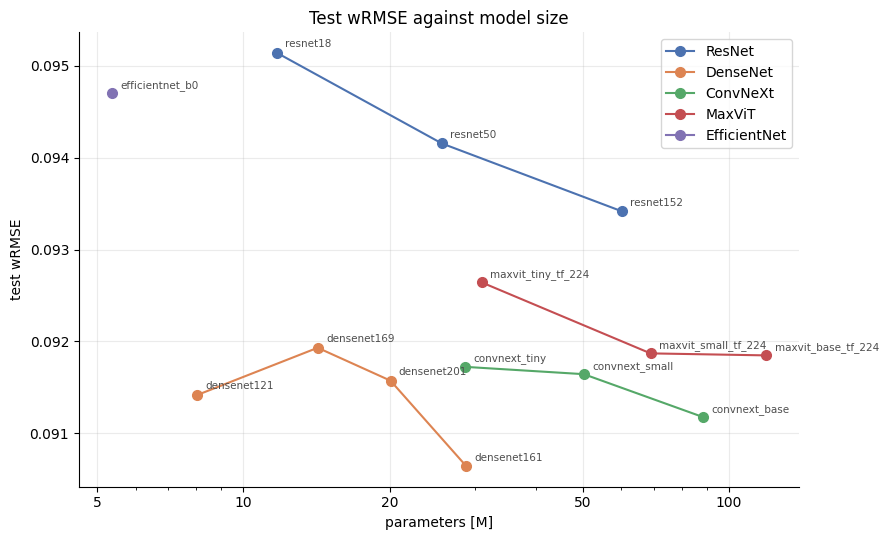

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for _prefix, (name, color) in FAMILIES.items():
    fam = results[results["family"] == name].sort_values("params [M]")
    ax.plot(fam["params [M]"], fam["test wRMSE"], "-o", color=color, label=name, ms=7)
    for arch, row in fam.iterrows():
        ax.annotate(arch, (row["params [M]"], row["test wRMSE"]), textcoords="offset points",
                    xytext=(6, 4), fontsize=7.5, color="0.3")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("parameters [M]")
ax.set_ylabel("test wRMSE")
ax.set_title("Test wRMSE against model size")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "benchmark_capacity.png", dpi=150, bbox_inches="tight")
plt.show()

## Questions analysis

Macro F1 per question on the test set, using the majority vote as the true label. Every
model scores 0.88 or more on Q1, Q2, Q6 and Q7, and under 0.61 on bulge size (Q5), bulge
shape (Q8), spiral winding (Q9) and the number of spiral arms (Q10). On any single question
the models differ by at most 0.04.

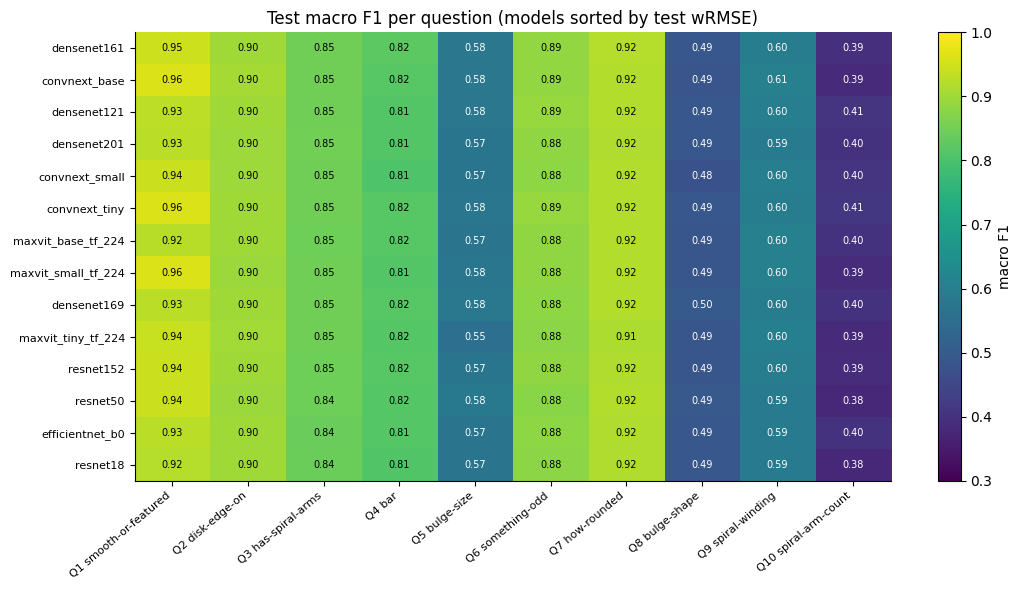

In [4]:
f1 = pd.DataFrame(
    {r["arch"].split(".")[0]: [q["f1_macro"] for q in r["test"]["questions"]] for r in runs},
    index=[f"Q{q} {name}" for q, name in enumerate(data.QUESTION_NAMES, start=1)],
).T.loc[results.index]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(f1, cmap="viridis", vmin=0.3, vmax=1.0, aspect="auto")
ax.set_xticks(range(f1.shape[1]))
ax.set_xticklabels(f1.columns, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(f1.shape[0]))
ax.set_yticklabels(f1.index, fontsize=8)
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]):
        v = f1.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v < 0.65 else "black")
fig.colorbar(im, ax=ax, label="macro F1")
ax.set_title("Test macro F1 per question (models sorted by test wRMSE)")
fig.tight_layout()
fig.savefig(FIG_DIR / "f1_per_question.png", dpi=150, bbox_inches="tight")
plt.show()

## Error analysis

Row-normalised confusion matrices for the two hardest questions: the diagonal is the
recall of each answer. Rare answers are absorbed by the dominant one: the best model
never predicts `boxy`, and recognises only 6-7% of galaxies with 4 or more spiral arms.

best model: densenet161


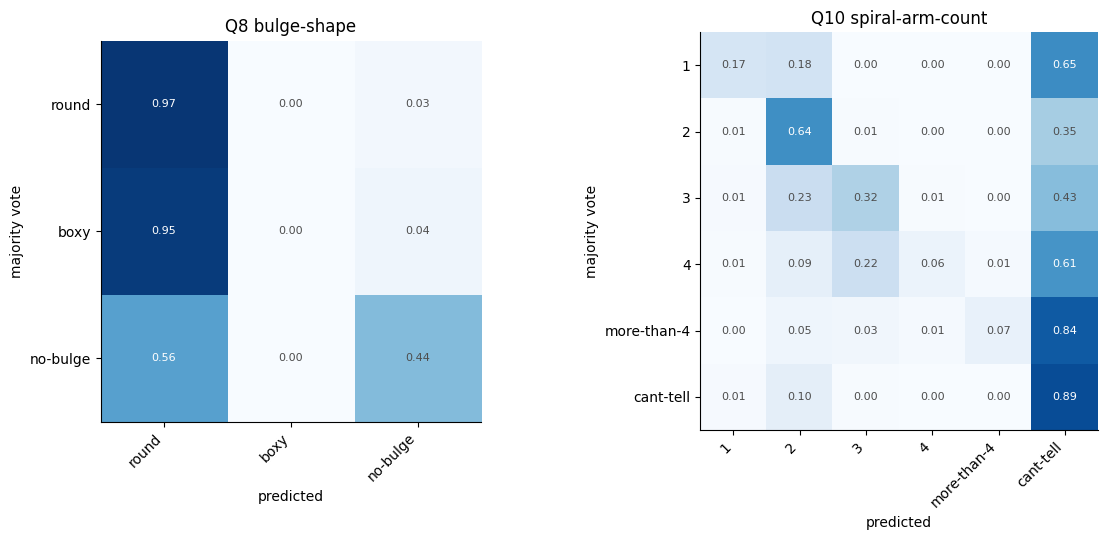

In [5]:
best = next(r for r in runs if r["arch"].split(".")[0] == results.index[0])
print(f"best model: {results.index[0]}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [3, 6]})
for ax, q in zip(axes, (8, 10), strict=True):
    question = best["test"]["questions"][q - 1]
    cm = np.array(question["confusion"], dtype=float)
    cm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(question["answers"]))
    ax.set_xticks(ticks)
    ax.set_xticklabels(question["answers"], rotation=45, ha="right")
    ax.set_yticks(ticks)
    ax.set_yticklabels(question["answers"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("majority vote")
    ax.set_title(f"Q{q} {question['name']}")
    for i in ticks:
        for j in ticks:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "0.3")
fig.tight_layout()
plt.show()

## Lower bound of the D-M loss

For one galaxy and question, the D-M loss is smallest when the predicted Dirichlet
collapses onto the observed fractions k/N, where it equals −Σ k_i log(k_i / N). No model
can know the observed fractions in advance, so this is a hard lower bound on the
validation loss, and the true achievable minimum lies above it.

In [6]:
_, val, _ = load_splits()
counts = np.nan_to_num(val.select_columns(data.campaign_cols()).to_pandas().to_numpy(np.float64))

floor = {}
for name, sl in zip(data.QUESTION_NAMES, data.QUESTION_SLICES, strict=True):
    k = counts[:, sl]
    n = k.sum(axis=1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        terms = np.where(k > 0, k * np.log(k / n), 0.0)
    floor[name] = -terms.sum() / len(counts)  # averaged over all galaxies, like the loss
floor = pd.Series(floor)

best_val_loss = min(r["val_loss"] for r in runs)
print(f"lower bound of the validation loss: {floor.sum():.2f}")
print(f"best validation loss reached:       {best_val_loss:.2f}")
print(f"excess over the bound:              {best_val_loss - floor.sum():.2f} "
      f"({100 * (best_val_loss - floor.sum()) / best_val_loss:.1f}% of the loss)")
(100 * floor / floor.sum()).round(1).rename("share of the bound [%]")

lower bound of the validation loss: 78.88
best validation loss reached:       87.34
excess over the bound:              8.46 (9.7% of the loss)


smooth-or-featured    28.9
disk-edge-on           3.2
has-spiral-arms        4.6
bar                    5.0
bulge-size            10.7
something-odd         17.7
how-rounded           15.7
bulge-shape            1.7
spiral-winding         6.3
spiral-arm-count       6.4
Name: share of the bound [%], dtype: float64

## Summary

- All 14 models land within a narrow wRMSE band, regardless of family or size, and they
  are weak on the same questions.
- About 90% of the validation loss is below the lower bound set by the labels themselves,
  so the ceiling comes from the votes, not from the architectures.
- The questions every model fails on are the deep, sparsely voted and imbalanced ones
  (Q8, Q10). `03_class_imbalance.ipynb` tests whether reweighting the loss or
  oversampling rare answers helps there.